# Notebook 01 — Data Exploration & EDA

This notebook performs **Exploratory Data Analysis (EDA)** on the **Sen1Floods11** dataset.

**Stages:**
1. Dataset structure overview
2. Visualize SAR imagery (VV & VH bands)
3. Visualize flood label masks
4. Check for NaN / invalid pixels
5. Pixel value distributions

## Step 1: Import Libraries & Setup

In [1]:
import os
import sys
sys.path.insert(0, '..')  # Add parent dir to path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import rasterio
import torch

# Set style
plt.rcParams['figure.facecolor'] = '#0d1117'
plt.rcParams['axes.facecolor'] = '#161b22'
plt.rcParams['axes.edgecolor'] = '#30363d'
plt.rcParams['text.color'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'white'
plt.rcParams['ytick.color'] = 'white'
plt.rcParams['font.family'] = 'DejaVu Sans'

print('Libraries loaded successfully!')


Libraries loaded successfully!


## Step 2: Dataset Structure Overview

In [2]:
# Dataset paths
S1_DIR = '../data/sen1floods11/S1Hand'
LABEL_DIR = '../data/sen1floods11/LabelHand'

s1_files = sorted([f for f in os.listdir(S1_DIR) if f.endswith('.tif')])
label_files = sorted([f for f in os.listdir(LABEL_DIR) if f.endswith('.tif')])

print(f'Total SAR images: {len(s1_files)}')
print(f'Total label masks: {len(label_files)}')
print(f'\nFirst 5 SAR files:')
for f in s1_files[:5]:
    print(f'  {f}')

# Read metadata from first image
with rasterio.open(os.path.join(S1_DIR, s1_files[0])) as src:
    print(f'\nImage Metadata:')
    print(f'  Shape: {src.read().shape} (Bands x H x W)')
    print(f'  CRS: {src.crs}')
    print(f'  Dtype: {src.dtypes}')
    print(f'  Resolution: {src.res}')


Total SAR images: 40
Total label masks: 40

First 5 SAR files:
  Ghana_103272_S1Hand.tif
  Ghana_1078550_S1Hand.tif
  Ghana_1089161_S1Hand.tif
  Ghana_11745_S1Hand.tif
  Ghana_128663_S1Hand.tif



Image Metadata:
  Shape: (2, 512, 512) (Bands x H x W)
  CRS: EPSG:4326
  Dtype: ('float32', 'float32')
  Resolution: (8.983152841195215e-05, 8.983152841195215e-05)


## Step 3: Visualize SAR Imagery (VV & VH Bands)

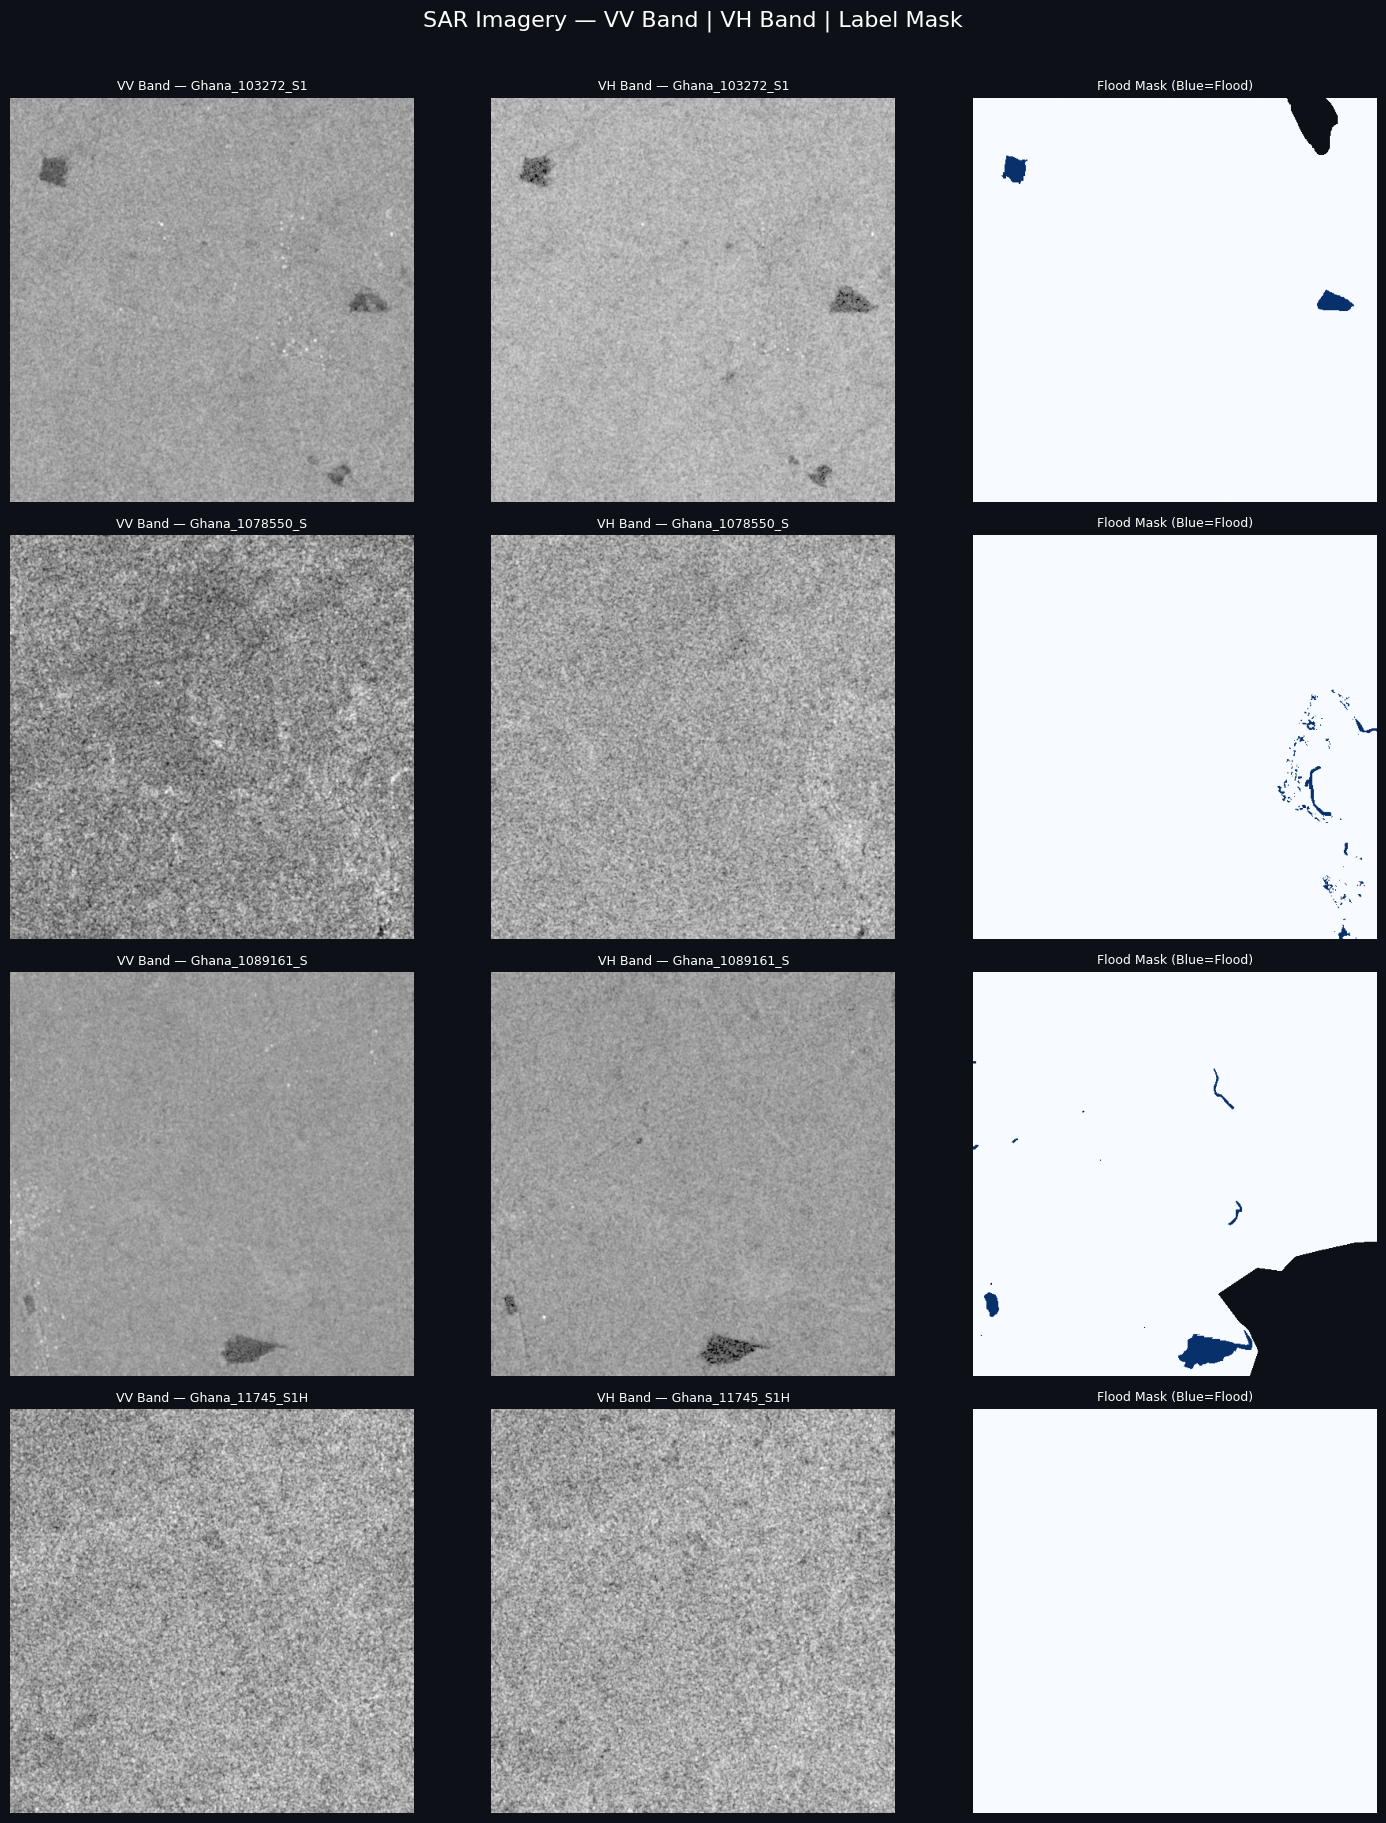

SAR sample visualization saved!


In [3]:
def load_sar(path):
    with rasterio.open(path) as src:
        data = src.read().astype(np.float32)
    return data

def load_label(path):
    with rasterio.open(path) as src:
        data = src.read(1).astype(np.float32)
    return data

# Visualize first 4 SAR images
fig, axes = plt.subplots(4, 3, figsize=(15, 18))
fig.suptitle('SAR Imagery — VV Band | VH Band | Label Mask', fontsize=16, color='white', y=1.01)

for i in range(4):
    s1 = load_sar(os.path.join(S1_DIR, s1_files[i]))
    label = load_label(os.path.join(LABEL_DIR, label_files[i]))

    vv = np.nan_to_num(s1[0], nan=-25)
    vh = np.nan_to_num(s1[1], nan=-30)
    label_masked = np.where(label == -1, np.nan, label)

    axes[i][0].imshow(vv, cmap='gray')
    axes[i][0].set_title(f'VV Band — {s1_files[i][:15]}', fontsize=9)
    axes[i][0].axis('off')

    axes[i][1].imshow(vh, cmap='gray')
    axes[i][1].set_title(f'VH Band — {s1_files[i][:15]}', fontsize=9)
    axes[i][1].axis('off')

    axes[i][2].imshow(label_masked, cmap='Blues', vmin=0, vmax=1)
    axes[i][2].set_title(f'Flood Mask (Blue=Flood)', fontsize=9)
    axes[i][2].axis('off')

plt.tight_layout()
plt.savefig('../data/eda_sar_samples.png', dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('SAR sample visualization saved!')


## Step 4: False-Color RGB Composite (VV, VH, VV-VH)

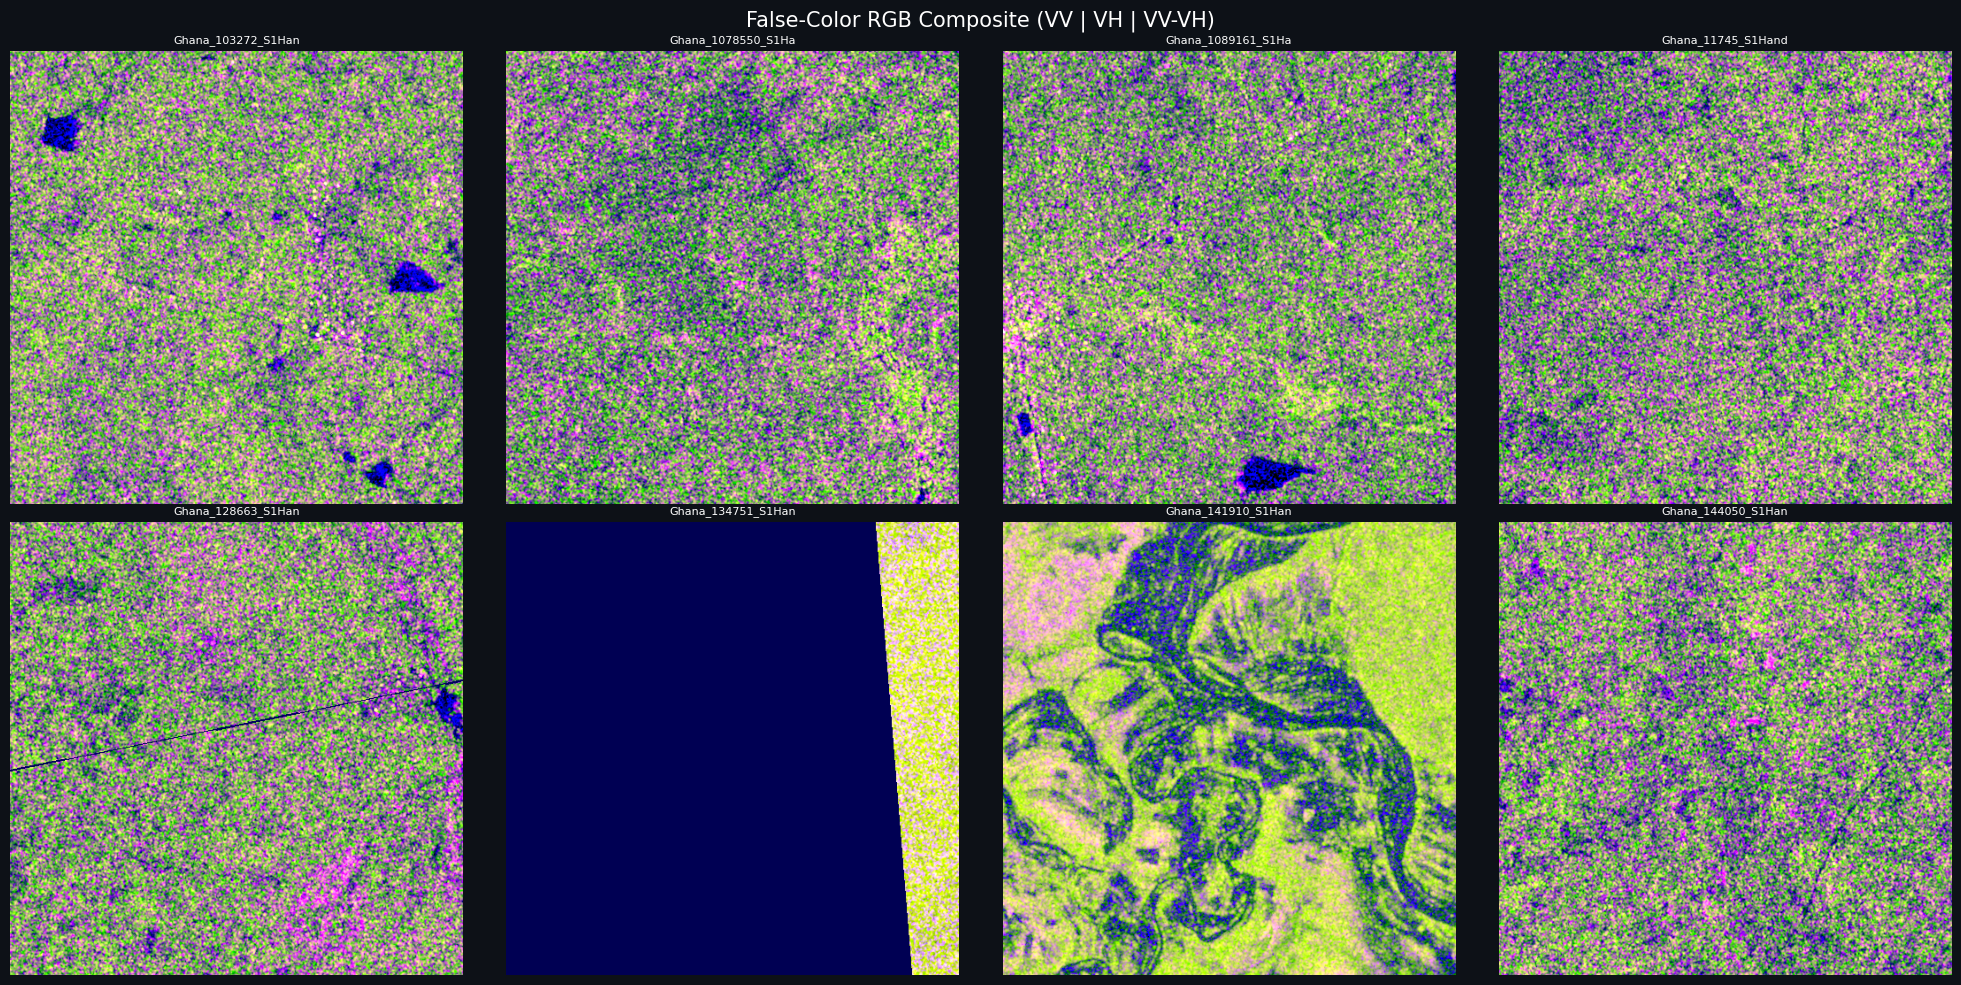

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle('False-Color RGB Composite (VV | VH | VV-VH)', fontsize=15, color='white')

for i in range(min(8, len(s1_files))):
    s1 = load_sar(os.path.join(S1_DIR, s1_files[i]))
    vv = np.nan_to_num(s1[0], nan=-25)
    vh = np.nan_to_num(s1[1], nan=-30)

    def normalize_band(b):
        b = np.clip(b, np.percentile(b, 2), np.percentile(b, 98))
        return (b - b.min()) / (b.max() - b.min() + 1e-8)

    rgb = np.stack([normalize_band(vv), normalize_band(vh), normalize_band(vv - vh)], axis=-1)
    ax = axes[i // 4][i % 4]
    ax.imshow(rgb)
    ax.set_title(s1_files[i][:18], fontsize=8)
    ax.axis('off')

plt.tight_layout()
plt.savefig('../data/eda_rgb_composites.png', dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()


## Step 5: NaN & Data Quality Checks

Files with NaN values: 4 / 40
Max NaN count in single image: 448962
Overall pixel range: [-56.69, 14.50] dB


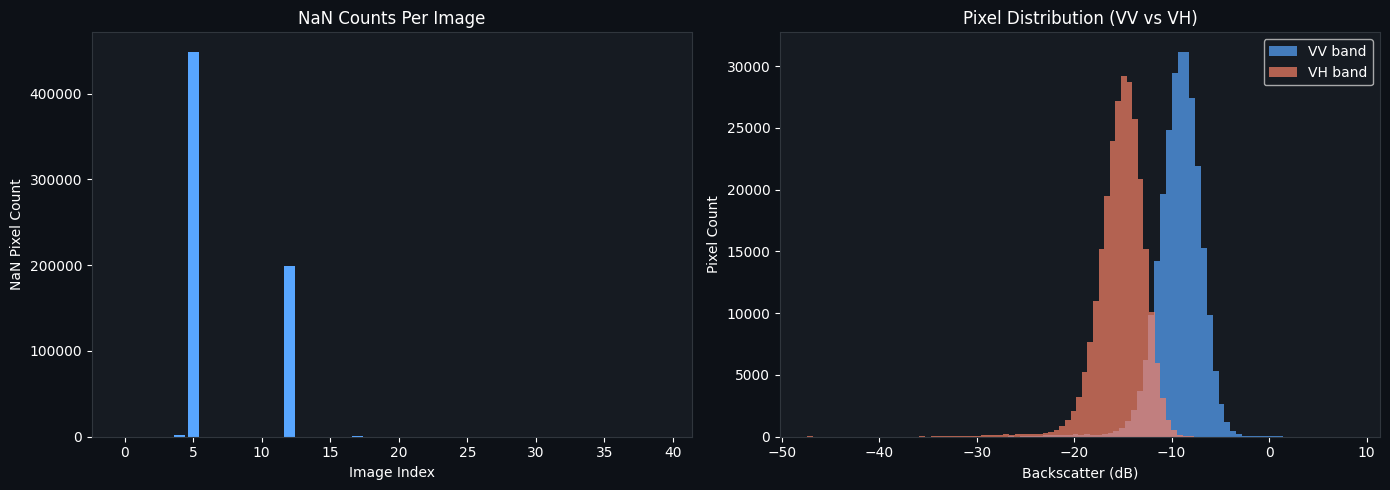

In [5]:
nan_counts = []
pixel_ranges = []

for fname in s1_files:
    s1 = load_sar(os.path.join(S1_DIR, fname))
    n_nan = int(np.isnan(s1).sum())
    nan_counts.append(n_nan)
    pixel_ranges.append((float(np.nanmin(s1)), float(np.nanmax(s1))))

print(f'Files with NaN values: {sum(1 for n in nan_counts if n > 0)} / {len(s1_files)}')
print(f'Max NaN count in single image: {max(nan_counts)}')
print(f'Overall pixel range: [{min(r[0] for r in pixel_ranges):.2f}, {max(r[1] for r in pixel_ranges):.2f}] dB')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(len(nan_counts)), nan_counts, color='#58a6ff')
axes[0].set_xlabel('Image Index')
axes[0].set_ylabel('NaN Pixel Count')
axes[0].set_title('NaN Counts Per Image')

# Pixel distribution of first image
s1_sample = load_sar(os.path.join(S1_DIR, s1_files[0]))
vv_vals = s1_sample[0][~np.isnan(s1_sample[0])].flatten()
vh_vals = s1_sample[1][~np.isnan(s1_sample[1])].flatten()
axes[1].hist(vv_vals, bins=80, alpha=0.7, label='VV band', color='#58a6ff')
axes[1].hist(vh_vals, bins=80, alpha=0.7, label='VH band', color='#f78166')
axes[1].set_xlabel('Backscatter (dB)')
axes[1].set_ylabel('Pixel Count')
axes[1].set_title('Pixel Distribution (VV vs VH)')
axes[1].legend()

plt.tight_layout()
plt.savefig('../data/eda_nan_distribution.png', dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()


## Step 6: Label Distribution (Flood vs Non-Flood)

Flood pixels:     314,272 (3.0%)
Non-flood pixels: 6,740,618 (64.3%)
Invalid pixels:   3,430,870 (32.7%)


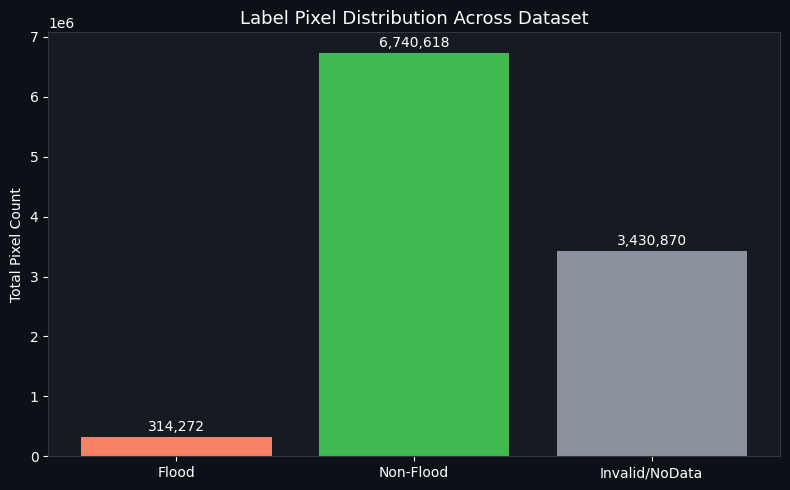

EDA complete! Insights saved.


In [6]:
flood_pixels = 0
non_flood_pixels = 0
invalid_pixels = 0

for fname in label_files:
    label = load_label(os.path.join(LABEL_DIR, fname))
    flood_pixels += int(np.sum(label == 1))
    non_flood_pixels += int(np.sum(label == 0))
    invalid_pixels += int(np.sum(label == -1))

total = flood_pixels + non_flood_pixels + invalid_pixels
print(f'Flood pixels:     {flood_pixels:,} ({100*flood_pixels/total:.1f}%)')
print(f'Non-flood pixels: {non_flood_pixels:,} ({100*non_flood_pixels/total:.1f}%)')
print(f'Invalid pixels:   {invalid_pixels:,} ({100*invalid_pixels/total:.1f}%)')

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(['Flood', 'Non-Flood', 'Invalid/NoData'],
              [flood_pixels, non_flood_pixels, invalid_pixels],
              color=['#f78166', '#3fb950', '#8b949e'])
ax.set_title('Label Pixel Distribution Across Dataset', fontsize=13)
ax.set_ylabel('Total Pixel Count')
for bar, val in zip(bars, [flood_pixels, non_flood_pixels, invalid_pixels]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1e5,
            f'{val:,}', ha='center', fontsize=10)
plt.tight_layout()
plt.savefig('../data/eda_label_distribution.png', dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('EDA complete! Insights saved.')
